<a href="https://colab.research.google.com/github/sredhagopan/AI-ML-Lab/blob/main/Data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Lab Exercise I: Data Pre-processing
### Date : 8 July 2026

### 1 & 2. Load Dataset and Display Basic Info


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

In [ ]:
# 1. Load the Titanic dataset
df = pd.read_csv('/content/titanic_data.csv')

# Keep a raw copy for final comparison
raw_df = df.copy()

# 2. Identify basic statistics and metadata
print("=== Titanic Dataset Info ===")
df.info()

print("\n=== Missing Values Per Column ===")
print(df.isnull().sum())

print(f"\nNumber of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")

=== Titanic Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 889 entries, 0 to 888
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     889 non-null    int64  
 1   pclass       889 non-null    int64  
 2   sex          889 non-null    object 
 3   age          713 non-null    float64
 4   sibsp        889 non-null    int64  
 5   parch        889 non-null    int64  
 6   fare         889 non-null    float64
 7   embarked     887 non-null    object 
 8   class        889 non-null    object 
 9   who          889 non-null    object 
 10  adult_male   889 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  887 non-null    object 
 13  alive        889 non-null    object 
 14  alone        889 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.2+ KB

=== Missing Values Per Column ===
survived         0
pclass           0
sex    

### 3. Exploratory Data Inspection


In [ ]:
print("=== First 5 Records ===")
display(df.head())

print("\n=== Last 5 Records ===")
display(df.tail())

print("\n=== Random Sample of 5 Records ===")
display(df.sample(5))

=== First 5 Records ===


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



=== Last 5 Records ===


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
884,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
885,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
886,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
887,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
888,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True



=== Random Sample of 5 Records ===


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
270,1,3,male,25.0,0,0,0.0000,S,Third,man,True,NaN,Southampton,yes,True
185,0,1,male,NaN,0,0,50.0000,S,First,man,True,A,Southampton,no,True
385,0,3,male,1.0,5,2,46.9000,S,Third,child,False,NaN,Southampton,no,False
728,1,1,female,29.0,0,0,211.3375,S,First,woman,False,B,Southampton,yes,True
294,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True


### 4. Handle Missing Values


In [ ]:
# 4. Handle Missing Values
# age (Numerical) - Fill with median
age_median = df['age'].median()
df['age'] = df['age'].fillna(age_median)

# deck (Categorical) - Fill with placeholder 'Unknown'
df['deck'] = df['deck'].fillna('Unknown')

# embarked (Categorical) - Fill with the mode
embarked_mode = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(embarked_mode)

# embark_town (Categorical) - Fill with the mode
embark_town_mode = df['embark_town'].mode()[0]
df['embark_town'] = df['embark_town'].fillna(embark_town_mode)

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64


### 5. Identify and Remove Duplicate Records

In [ ]:
duplicates = df.duplicated()
print(f"Number of duplicate rows found: {duplicates.sum()}")

# Remove duplicates in-place
df.drop_duplicates(inplace=True)
print(f"Dataset shape after removing duplicates: {df.shape}")

### 6 & 7. Detect and Handle Outliers


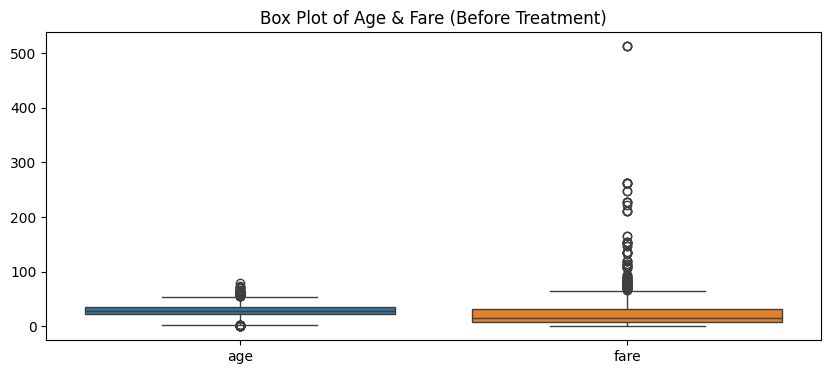

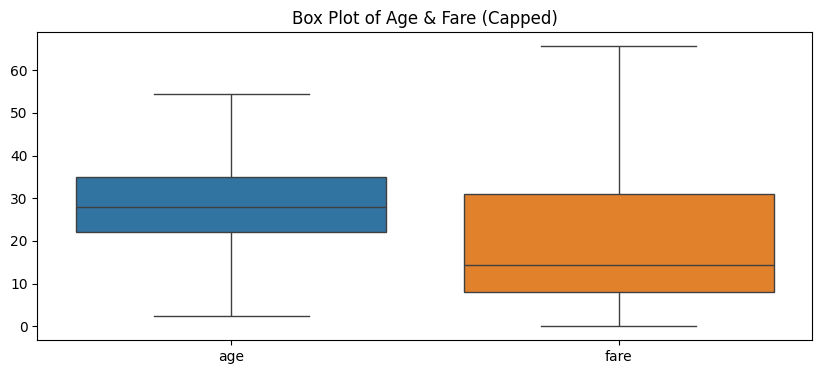

In [ ]:
# 6. Detect Outliers using Box Plots before processing
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[['age', 'fare']])
plt.title("Box Plot of Age & Fare (Before Treatment)")
plt.show()

# 7. Outlier handling function using IQR capping
def cap_outliers(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values
    dataframe[column] = np.clip(dataframe[column], lower_bound, upper_bound)
    return dataframe

# Process numerical columns
df = cap_outliers(df, 'age')
df = cap_outliers(df, 'fare')

# Visualize after capping
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[['age', 'fare']])
plt.title("Box Plot of Age & Fare (Capped)")
plt.show()

### 8. Convert Categorical Variables into Numerical Form

In [ ]:
# 8. Convert Categorical Variables into Numerical Form
# Label Encoding for sex
le = LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])

# One-Hot Encoding for embarked
df = pd.get_dummies(df, columns=['embarked'], drop_first=True, dtype=int)

display(df[['sex', 'sex_encoded', 'embarked_Q', 'embarked_S']].head())

,sex,sex_encoded,embarked_Q,embarked_S
0,male,1,0,1
1,female,0,0,0
2,female,0,0,1
3,female,0,0,1
4,male,1,0,1


### 9. Feature Scaling


In [ ]:
# 9. Apply Feature Scaling techniques
# Min-Max Normalization on age
min_max = MinMaxScaler()
df['age_MinMax'] = min_max.fit_transform(df[['age']])

# Standardization (Z-score Scaling) on fare
scaler = StandardScaler()
df['fare_scaled'] = scaler.fit_transform(df[['fare']])

display(df[['age', 'age_MinMax', 'fare', 'fare_scaled']].head())

,age,age_MinMax,fare,fare_scaled
0,22.0,0.375000,7.2500,-0.822086
1,38.0,0.682692,65.6125,2.028639
2,26.0,0.451923,7.9250,-0.789116
3,35.0,0.625000,53.1000,1.417464
4,35.0,0.625000,8.0500,-0.783010


### 10 & 11. Correlation Analysis & Heatmap

In [ ]:
# Select numeric columns for correlation
numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix Heatmap")
plt.show()

### 12, 13 & 14. Feature Engineering, Data Type Conversion & Noise Cleaning

In [ ]:
# 12. Create new features (Feature Engineering)
df['family_size'] = df['sibsp'] + df['parch'] + 1

# 13. Convert Data Types
df['fare'] = df['fare'].astype(float)
df['age'] = df['age'].astype(float)

# 14. Handle Inconsistent and Noisy Data
# Clean string values in 'class'
df['class'] = df['class'].str.strip().str.title()

display(df[['family_size', 'fare', 'age', 'class']].head())

,family_size,fare,age,class
0,2,7.2500,22.0,Third
1,2,65.6125,38.0,First
2,1,7.9250,26.0,Third
3,2,53.1000,35.0,First
4,1,8.0500,35.0,Third


### 15 & 16. Split Dataset & Data Balancing


In [ ]:
# 15. Split dataset into training and testing sets
from sklearn.utils import resample

features = ['pclass', 'sex_encoded', 'age_MinMax', 'fare_scaled', 'family_size', 'embarked_Q', 'embarked_S']
X = df[features]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set balance before Oversampling: \n{y_train.value_counts(normalize=True)}")

# 16. Perform data balancing using oversampling
train_df_temp = pd.concat([X_train, y_train], axis=1)
majority = train_df_temp[train_df_temp['survived'] == 0]
minority = train_df_temp[train_df_temp['survived'] == 1]

minority_upsampled = resample(minority, replace=True, n_samples=len(majority), random_state=42)
balanced_train = pd.concat([majority, minority_upsampled])

print(f"\nBalanced Training set class counts: \n{balanced_train['survived'].value_counts()}")

Training set balance before Oversampling: 
survived
0    0.614627
1    0.385373
Name: proportion, dtype: float64

Balanced Training set class counts: 
survived
0    437
1    437
Name: count, dtype: int64


### 17 & 18. Visualize and Compare Before vs After Pre-processing

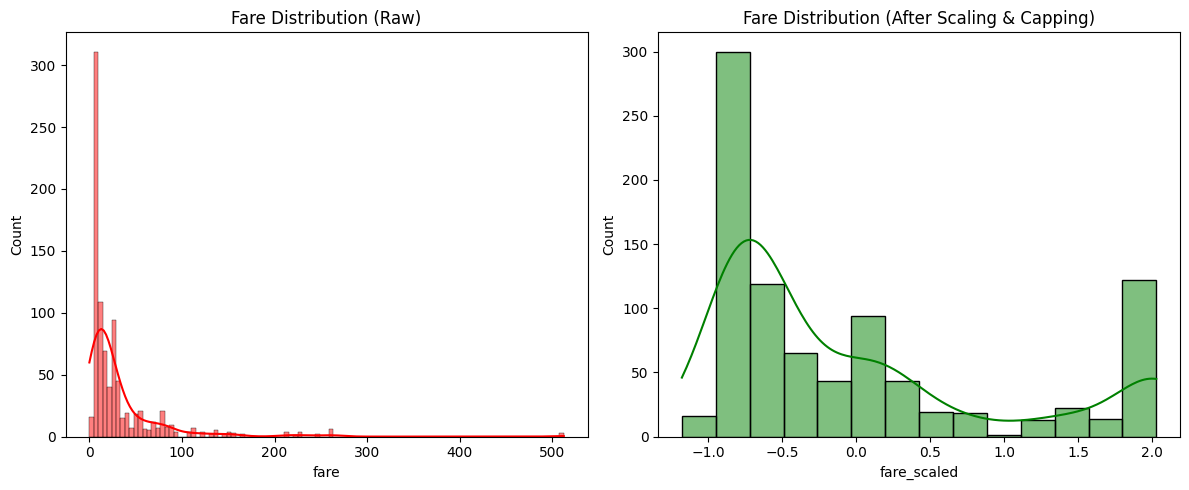

In [ ]:
# 17. Visualize distribution of numerical features before and after pre-processing
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(raw_df['fare'].dropna(), kde=True, ax=axes[0], color='red')
axes[0].set_title("Fare Distribution (Raw)")

sns.histplot(df['fare_scaled'], kde=True, ax=axes[1], color='green')
axes[1].set_title("Fare Distribution (After Scaling & Capping)")

plt.tight_layout()
plt.show()

### 19 & 20. Save and Summarize

In [ ]:
# 19. Save the cleaned and preprocessed dataset
df.to_csv('preprocessed_dataset.csv', index=False)
print("Cleaned and preprocessed dataset saved as 'preprocessed_dataset.csv'.")

# 18. Compare the dataset before and after preprocessing and summarize
print("\n--- COMPARISON SUMMARY ---")
print(f"Raw dataset shape: {raw_df.shape}")
print(f"Cleaned dataset shape: {df.shape}")
print("1. Missing values handled for age, deck, and embarked.")
print("2. Handled outliers on age and fare by applying IQR capping.")
print("3. Encoded sex (Label) and embarked (One-Hot).")
print("4. Scaled age (Min-Max) and fare (Standardization).")
print("5. Engineered new feature: family_size.")
print("6. Balanced target dataset splits using Random Oversampling.")

Cleaned and preprocessed dataset saved as 'preprocessed_dataset.csv'.

--- COMPARISON SUMMARY ---
Raw dataset shape: (889, 15)
Cleaned dataset shape: (889, 20)
1. Missing values handled for age, deck, and embarked.
2. Handled outliers on age and fare by applying IQR capping.
3. Encoded sex (Label) and embarked (One-Hot).
4. Scaled age (Min-Max) and fare (Standardization).
5. Engineered new feature: family_size.
6. Balanced target dataset splits using Random Oversampling.
